In [8]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import IsolationForest
import joblib

In [9]:
df = pd.read_csv('dados/station_data_dataverse.csv')
df.columns = df.columns.str.lower()   
print(df.shape)
print(df.columns.tolist())

(3395, 24)
['sessionid', 'kwhtotal', 'dollars', 'created', 'ended', 'starttime', 'endtime', 'chargetimehrs', 'weekday', 'platform', 'distance', 'userid', 'stationid', 'locationid', 'managervehicle', 'facilitytype', 'mon', 'tues', 'wed', 'thurs', 'fri', 'sat', 'sun', 'reportedzip']


In [10]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 3395 entries, 0 to 3394
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sessionid       3395 non-null   int64  
 1   kwhtotal        3395 non-null   float64
 2   dollars         3395 non-null   float64
 3   created         3395 non-null   str    
 4   ended           3395 non-null   str    
 5   starttime       3395 non-null   int64  
 6   endtime         3395 non-null   int64  
 7   chargetimehrs   3395 non-null   float64
 8   weekday         3395 non-null   str    
 9   platform        3395 non-null   str    
 10  distance        2330 non-null   float64
 11  userid          3395 non-null   int64  
 12  stationid       3395 non-null   int64  
 13  locationid      3395 non-null   int64  
 14  managervehicle  3395 non-null   int64  
 15  facilitytype    3395 non-null   int64  
 16  mon             3395 non-null   int64  
 17  tues            3395 non-null   int64  
 18 

,sessionid,kwhtotal,dollars,starttime,endtime,chargetimehrs,distance,userid,stationid,locationid,managervehicle,facilitytype,mon,tues,wed,thurs,fri,sat,sun,reportedzip
count,3.395000e+03,3395.000000,3395.000000,3395.000000,3395.000000,3395.000000,2330.000000,3.395000e+03,3395.000000,3395.000000,3395.000000,3395.000000,3395.000000,3395.000000,3395.000000,3395.000000,3395.000000,3395.000000,3395.000000,3395.000000
mean,5.487001e+06,5.809629,0.118268,13.743446,16.455965,2.841488,18.652378,5.742395e+07,576789.678056,629934.460677,0.595582,2.428571,0.181443,0.187040,0.210015,0.216495,0.179676,0.018262,0.007069,0.703976
std,2.590657e+06,2.892727,0.492562,3.204370,3.406732,1.507472,11.420571,2.674772e+07,257486.310402,255620.993849,0.490851,0.811204,0.385442,0.390001,0.407379,0.411916,0.383974,0.133918,0.083793,0.456569
min,1.004821e+06,0.000000,0.000000,0.000000,0.000000,0.012500,0.856911,1.042767e+07,129465.000000,125372.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.234666e+06,4.350000,0.000000,11.000000,14.000000,2.110278,5.135871,3.329548e+07,369001.000000,481066.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,5.451498e+06,6.230000,0.000000,13.000000,16.000000,2.808889,21.023826,4.924181e+07,549414.000000,503205.000000,1.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,7.746644e+06,6.830000,0.000000,17.000000,20.000000,3.544167,27.285053,8.188052e+07,864630.000000,878393.000000,1.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,9.998981e+06,23.680000,7.500000,23.000000,23.000000,55.238056,43.059292,9.834581e+07,995505.000000,978130.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [11]:
df.columns = df.columns.str.lower()

colunas_uteis = ['sessionid', 'userid', 'created', 'ended', 'kwhtotal', 'chargetimehrs', 'starttime']
df = df[colunas_uteis].drop_duplicates()

df['created'] = pd.to_datetime(df['created'], errors='coerce')
df['ended'] = pd.to_datetime(df['ended'], errors='coerce')

df = df.dropna(subset=['userid', 'kwhtotal', 'chargetimehrs', 'starttime'])
df = df[(df['kwhtotal'] > 0) & (df['chargetimehrs'] > 0)]
df.shape

(3340, 7)

In [12]:
colunas = ['kwhtotal', 'chargetimehrs', 'starttime']
X = df[colunas]

modelo = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
modelo.fit(X)

df['rotulo'] = modelo.predict(X)
df['score'] = modelo.decision_function(X)
df['rotulo'].value_counts()

rotulo
 1    3173
-1     167
Name: count, dtype: int64

In [21]:
for c in [0.01, 0.02, 0.05]:
    m = IsolationForest(n_estimators=100, contamination=c, random_state=42).fit(X)
    print(c, (m.predict(X) == -1).sum())

0.01 34
0.02 67
0.05 167


In [22]:
m01 = IsolationForest(n_estimators=100, contamination=0.01, random_state=42).fit(X)

so_05 = df[(df['rotulo'] == -1) & (m01.predict(X) == 1)]
print(len(so_05))

print(so_05[colunas].describe())
print(df[colunas].describe())

133
         kwhtotal  chargetimehrs   starttime
count  133.000000     133.000000  133.000000
mean     9.975940       3.022341   15.007519
std      7.256595       2.483451    4.321364
min      0.010000       0.021111    0.000000
25%      1.370000       0.810278   12.000000
50%     11.860000       3.021389   16.000000
75%     16.310000       3.860556   18.000000
max     21.200000       9.836944   23.000000
          kwhtotal  chargetimehrs    starttime
count  3340.000000    3340.000000  3340.000000
mean      5.905296       2.880775    13.729641
std       2.817906       1.480298     3.202316
min       0.010000       0.021111     0.000000
25%       4.470000       2.144931    11.000000
50%       6.280000       2.826667    13.000000
75%       6.840000       3.561597    17.000000
max      23.680000      55.238056    23.000000


In [13]:
df['media_usuario'] = df.groupby('userid')['kwhtotal'].transform('mean')
df['regra_dobro'] = df['kwhtotal'] > 2 * df['media_usuario']
df['regra_dobro'].sum()

np.int64(16)

In [15]:
df['anomalia'] = (df['rotulo'] == -1) | df['regra_dobro']

df['motivo'] = ''
df.loc[df['rotulo'] == -1, 'motivo'] += 'padrão atípico (modelo); '
df.loc[df['regra_dobro'], 'motivo'] += 'mais que 2x a média do usuário; '

df['anomalia'].sum()

np.int64(175)

In [16]:
u = df['userid'].iloc[0]
d = df[df['userid'] == u]
print('média:', d['kwhtotal'].mean())
print('sessões acima do dobro:', (d['kwhtotal'] > 2 * d['kwhtotal'].mean()).sum())
print('regra_dobro desse usuário:', d['regra_dobro'].sum())

média: 6.031309523809524
sessões acima do dobro: 14
regra_dobro desse usuário: 14


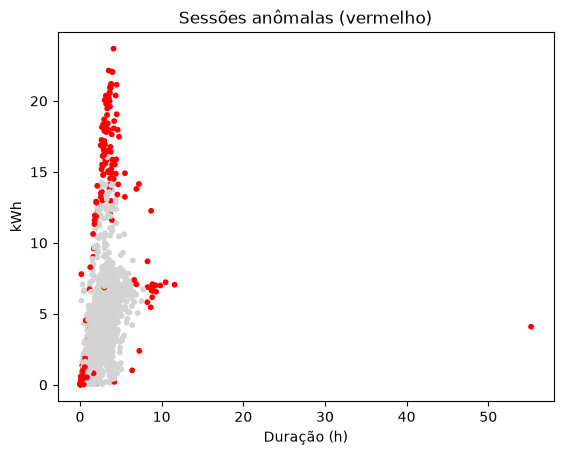

,kwhtotal,chargetimehrs,starttime,userid,motivo
955,20.37,3.162500,1,78908148,padrão atípico (modelo);
919,19.79,3.206667,1,78908148,padrão atípico (modelo);
972,23.68,4.106667,7,78908148,padrão atípico (modelo);
947,22.14,3.518333,5,78908148,padrão atípico (modelo);
920,16.88,2.531389,0,78908148,padrão atípico (modelo);
935,18.70,2.953333,3,78908148,padrão atípico (modelo);
944,20.06,3.016389,4,78908148,padrão atípico (modelo);
952,18.15,2.682778,23,78908148,padrão atípico (modelo);
932,18.35,2.835556,5,78908148,padrão atípico (modelo);
933,12.83,1.999444,0,78908148,padrão atípico (modelo);


In [17]:
cores = df['anomalia'].map({True: 'red', False: 'lightgray'})
plt.scatter(df['chargetimehrs'], df['kwhtotal'], c=cores, s=10)
plt.xlabel('Duração (h)')
plt.ylabel('kWh')
plt.title('Sessões anômalas (vermelho)')
plt.show()

df[df['anomalia']].sort_values('score').head(20)[colunas +['userid', 'motivo']]


In [18]:
medias = df.groupby('userid')['kwhtotal'].mean().to_dict()

def detectar(sessao):
    x = pd.DataFrame([sessao], columns=colunas)
    motivos = []
    if modelo.predict(x)[0] == -1:
        motivos.append('padrão atípico (Isolation Forest)')
    media = medias.get(sessao['userid'])
    if media is None:
        motivos.append('usuário sem histórico / não cadastrado')
    elif sessao['kwhtotal'] > 2 * media:
        motivos.append('consumo acima do dobro da média do usuário')
    return {'anomala': bool(motivos), 'motivos': motivos}

normal = {'userid': df['userid'].iloc[0], 'kwhtotal': 10, 'chargetimehrs': 3, 'starttime': 9}
absurda ={'userid': df['userid'].iloc[0], 'kwhtotal': 200, 'chargetimehrs': 0.2, 'starttime': 3}
print(detectar(normal))
print(detectar(absurda))

Path('modelos').mkdir(exist_ok=True)
joblib.dump(modelo, 'modelos/isolation_forest.joblib')

{'anomala': False, 'motivos': []}
{'anomala': True, 'motivos': ['padrão atípico (Isolation Forest)', 'consumo acima do dobro da média do usuário']}


['modelos/isolation_forest.joblib']

In [19]:
limite = {'userid': df['userid'].iloc[0], 'kwhtotal': 13, 'chargetimehrs': 3, 'starttime': 9}
print(detectar(limite))

{'anomala': True, 'motivos': ['padrão atípico (Isolation Forest)', 'consumo acima do dobro da média do usuário']}


In [20]:
so_regra = df[(df['regra_dobro']) & (df['rotulo'] == 1)]
print(len(so_regra))

exemplo = so_regra.iloc[0]
print(detectar(exemplo[['userid'] + colunas].to_dict()))

8
{'anomala': True, 'motivos': ['consumo acima do dobro da média do usuário']}
